<a href="https://colab.research.google.com/github/ntienvo/ML-lab/blob/main/Lab02_ComputerVision_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2 — Computer Vision: Image Classification Pipeline
**Dataset:** scikit-learn Digits  
**Task:** Multi-class image classification

## Overview
In this lab, you will build an end-to-end computer vision pipeline using conventional machine learning models. You will inspect images and labels, prepare image features, train classifiers, evaluate performance, and investigate classification errors.

The dataset contains small grayscale images of handwritten digits from 0 to 9. Each image is 8 × 8 pixels. The dataset is bundled with scikit-learn, so no external download is required.

## Learning objectives
By the end of this lab, you should be able to:
- Load and visualize an image dataset.
- Interpret image dimensions, pixel intensities, and class distributions.
- Convert images into feature vectors for conventional ML models.
- Train and compare baseline classifiers.
- Evaluate a multi-class classifier using accuracy, precision, recall, F1-score, and a confusion matrix.
- Visualize misclassified images and discuss limitations of flattened image representations.

## Important rules
- Use `random_state=42` for reproducibility.
- Keep the test set separate from model selection.
- Fit data-dependent preprocessing only on training data.
- Complete the TODOs and answer the discussion questions.
- This lab uses conventional ML classifiers; implementing a CNN is outside the required scope.

## Part 0 — Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

In [ ]:
RANDOM_STATE = 42

## Part 1 — Load and understand the images

### Task 1.1 — Load the dataset
Load the dataset using `load_digits()`. Keep:
- `images`: images with shape `(n_samples, 8, 8)`
- `X`: flattened feature vectors with shape `(n_samples, 64)`
- `y`: digit labels from 0 to 9

Pixel values range from 0 to 16. In the raw images, larger values represent stronger ink intensity.

**TODO:** Load the dataset and create these variables.

In [ ]:
# TODO: Load the dataset.
digits = load_digits()

# TODO: Assign images and labels.
images, y = digits.images, digits.target

# TODO: Flatten each image into 64 features.
X = images.reshape(len(images), 64)

# YOUR CODE HERE

In [ ]:
# Run after completing Task 1.1.
print("Images shape:", images.shape)
print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Pixel intensity range:", images.min(), "to", images.max())
print("Classes:", np.unique(y))

Images shape: (1797, 8, 8)
Feature matrix shape: (1797, 64)
Labels shape: (1797,)
Pixel intensity range: 0.0 to 16.0
Classes: [0 1 2 3 4 5 6 7 8 9]


### Task 1.2 — Visualize examples
Display a grid containing at least 10 images and their labels.

**TODO:** Use `plt.subplots`, `imshow`, and `set_title`. Hide axes and use a grayscale colormap.

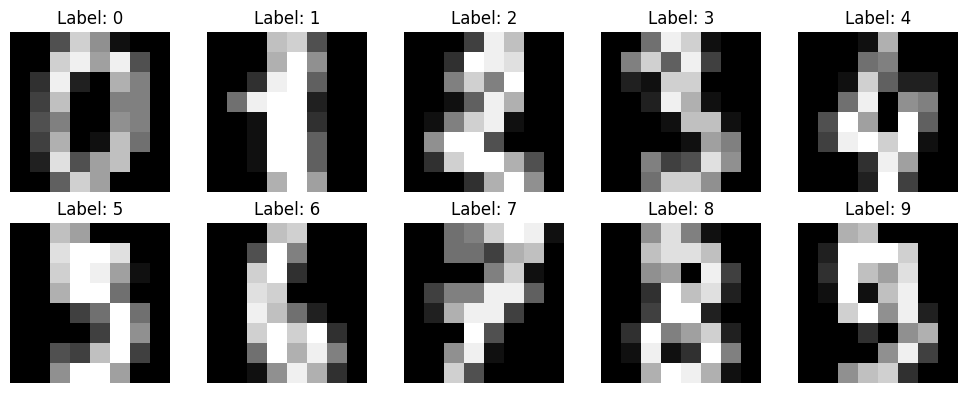

In [ ]:
# TODO: Plot 10 images in a grid with their digit labels.
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=16)
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Task 1.3 — Explore class distribution
Count examples for each digit and visualize the counts in a bar chart.

**TODO:** Create a Pandas Series or DataFrame of class counts and plot it.

,count
0,178
1,182
2,177
3,183
4,181
5,182
6,181
7,179
8,174
9,180


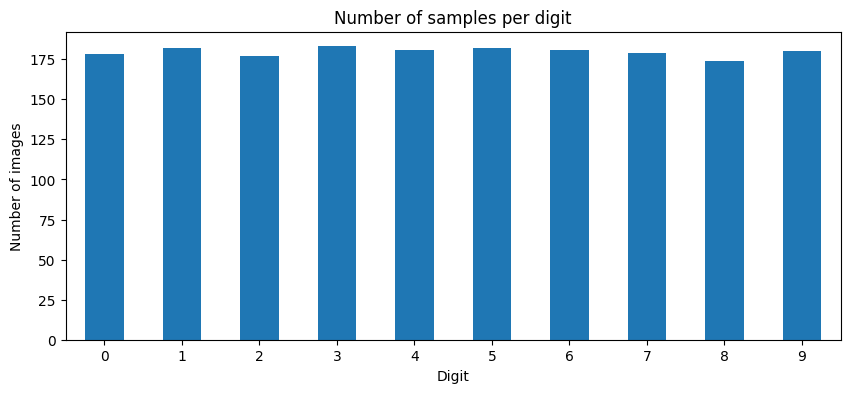

In [ ]:
# TODO: Count the number of samples for each digit.
# TODO: Plot a bar chart with digits 0–9 on the x-axis.

counts = pd.Series(y).value_counts().sort_index()

display(counts.to_frame(name="count"))

counts.plot(kind="bar", figsize=(10,4))

plt.title("Number of samples per digit")
plt.ylabel("Number of images")
plt.xlabel("Digit")
plt.xticks(rotation=0)
plt.show()

### Discussion questions
1. What do the dimensions `(n_samples, 8, 8)` represent?
2. Why is `X` shaped `(n_samples, 64)`?
3. What do low and high pixel intensities represent?
4. Is the dataset balanced across the ten digit classes?
5. What information might be lost when an image is flattened into a vector?

## Part 2 — Prepare image features
### Task 2.1 — Normalize pixel intensities
Create `X_norm` by converting `X` to floating-point values and dividing by `X.max()`. For this dataset, the maximum pixel value is 16, so the normalized values should be between 0 and 1.

Also use scikit-learn's `MinMaxScaler` to create `X_norm_sklearn`. Compare the first image after the two transformations. In the next task, display both versions.

**TODO:** Normalize `X`, create `X_norm_sklearn` with `MinMaxScaler`, and print the ranges. Keep the variables `X_norm` and `X_norm_sklearn`.

In [ ]:
# TODO: Normalize pixel values using the maximum pixel value.
X_norm = X.astype(float) / X.max()

# TODO: Apply MinMaxScaler to X for comparison with the manual normalization.
scaler = MinMaxScaler()
X_norm_sklearn = scaler.fit_transform(X)

# TODO: Print the minimum and maximum of both transformed matrices.
print("Normalized range:"),X_norm.min(), "to", X_norm.max()

Normalized range:


(None, np.float64(0.0), 'to', np.float64(1.0))

### Task 2.2 — Compare original and normalized images
Choose one image. Display the original image, the manually normalized image, and the image transformed with `MinMaxScaler` side by side.

**TODO:** Use three subplots and the same grayscale colormap. For normalized images, set `vmin=0` and `vmax=1` so the intensity scales are comparable.

[[0.  0.  0.3 0.8 0.6 0.1 0.  0. ]
 [0.  0.  0.8 0.9 0.6 0.9 0.3 0. ]
 [0.  0.2 0.9 0.1 0.  0.7 0.5 0. ]
 [0.  0.2 0.8 0.  0.  0.5 0.5 0. ]
 [0.  0.3 0.5 0.  0.  0.6 0.5 0. ]
 [0.  0.2 0.7 0.  0.1 0.8 0.4 0. ]
 [0.  0.1 0.9 0.3 0.6 0.8 0.  0. ]
 [0.  0.  0.4 0.8 0.6 0.  0.  0. ]]
[[0.  0.  0.3 0.8 0.6 0.1 0.  0. ]
 [0.  0.  0.8 0.9 0.6 0.9 0.3 0. ]
 [0.  0.2 0.9 0.1 0.  0.7 0.5 0. ]
 [0.  0.3 0.8 0.  0.  0.5 0.5 0. ]
 [0.  0.4 0.5 0.  0.  0.6 0.6 0. ]
 [0.  0.2 0.7 0.  0.1 0.8 0.4 0. ]
 [0.  0.1 0.9 0.3 0.6 0.8 0.  0. ]
 [0.  0.  0.4 0.8 0.6 0.  0.  0. ]]


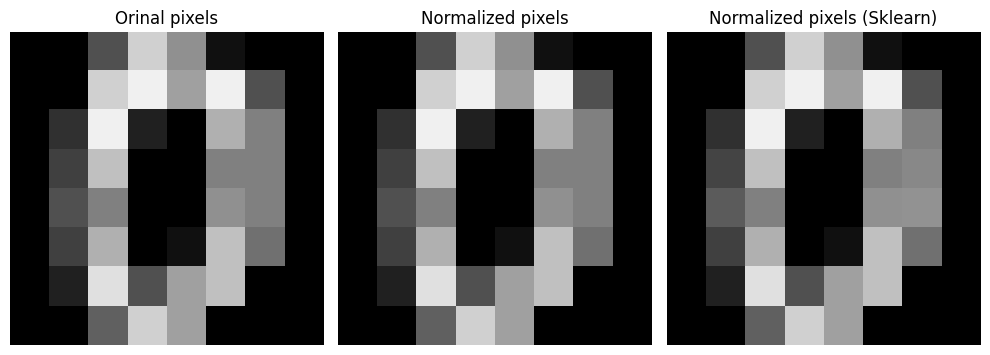

In [ ]:
# TODO: Select an image index (for example, sample_index = 0).
# TODO: Create three subplots: original, manually normalized, MinMaxScaler.
# TODO: Reshape feature vectors to (8, 8) before displaying them.
sample_index = 0

print(np.round(X_norm[sample_index].reshape(8,8),1))
print(np.round(X_norm_sklearn[sample_index].reshape(8,8),1))

fig, axes = plt.subplots(1, 3, figsize = (10, 4))
axes[0].imshow(images[sample_index], cmap="gray", vmin = 0, vmax = 16)
axes[0].set_title("Orinal pixels")

axes[1].imshow(X_norm[sample_index].reshape(8,8), cmap="gray", vmin = 0, vmax = 1)
axes[1].set_title("Normalized pixels")

axes[2].imshow(X_norm_sklearn[sample_index].reshape(8,8), cmap="gray", vmin = 0, vmax = 1)
axes[2].set_title("Normalized pixels (Sklearn)")

for ax in axes:
  ax.axis("off")

plt.tight_layout()
plt.show()



### Discussion questions
1. Does dividing pixel intensities by 16 change the image's shape?
2. Why can consistent pixel scaling be useful?
3. Does manual division by the fixed maximum use information from other samples, or is it applied independently to each pixel?
4. How does the `MinMaxScaler` result compare with manual division? Why might the results differ for individual pixel positions?
5. Why should a data-dependent scaler normally be fitted using training data only?

## Part 3 — Train/test split
Use 80% of samples for training and 20% for testing. Stratify by `y` and set `random_state=42`. Use `X_norm` as the feature matrix for the model experiments.

**TODO:** Split `X_norm` and `y` into training and test sets. Print their shapes and class distributions.

In [ ]:
# TODO: Use train_test_split with test_size=0.20,
# random_state=RANDOM_STATE, and stratify=y.
X_train, X_test, y_train, y_test = None, None, None, None

# YOUR CODE HERE

### Discussion questions
1. Why is stratification useful for a ten-class classification task?
2. Why should the test set not be used repeatedly to choose model settings?
3. Why is it important to keep the labels aligned with the correct images?

## Part 4 — Build a baseline classifier

A baseline provides a reference point for judging whether a trained model learns useful patterns.

### Task 4.1
Train `DummyClassifier(strategy="most_frequent")`. Evaluate its test accuracy and weighted F1-score.

**TODO:** Fit the baseline, predict the test labels, and report the metrics.

In [ ]:
# TODO: Create and fit the baseline classifier.
baseline = None

# TODO: Predict y for X_test.
baseline_pred = None

# TODO: Print accuracy and weighted F1-score.

### Discussion questions
1. Why is a majority-class baseline useful even if it is expected to perform poorly?
2. Why might weighted F1 be useful alongside accuracy?

## Part 5 — Train conventional image classifiers

We will compare Logistic Regression and Support Vector Machine (SVM). These are conventional ML methods, not deep neural networks.

### Task 5.1 — Logistic Regression
Build a pipeline containing `StandardScaler()` followed by `LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)`. Fit on training data and predict the test set.

**TODO:** Complete the pipeline.

In [ ]:
# TODO: Build the Logistic Regression pipeline.
logreg_pipeline = None

# TODO: Fit on X_train and y_train.
# TODO: Predict the test labels and store them in logreg_pred.

### Task 5.2 — Support Vector Machine
Build a pipeline containing `StandardScaler()` followed by `SVC(kernel="rbf")`. Fit and predict.

**TODO:** Complete the pipeline.

In [ ]:
# TODO: Build the SVM pipeline.
svm_pipeline = None

# TODO: Fit on X_train and y_train.
# TODO: Predict the test labels and store them in svm_pred.

### Task 5.3 — Compare models
Compare DummyClassifier, Logistic Regression, and SVM using:
- accuracy
- macro precision
- macro recall
- macro F1
- weighted F1

Use `zero_division=0` for precision, recall, and F1.

**TODO:** Create a reusable evaluation function and a comparison DataFrame.

In [ ]:
def evaluate_multiclass(y_true, y_pred):
    # TODO: Return accuracy, macro precision, macro recall,
    # macro F1, and weighted F1.
    raise NotImplementedError

# TODO: Build a comparison DataFrame for all three models.

### Discussion questions
1. Which model performs best according to macro F1?
2. Do accuracy and macro F1 tell exactly the same story?
3. Why might standardization affect Logistic Regression and SVM?
4. Why is this experiment not equivalent to training a CNN?

## Part 6 — Confusion matrix and error analysis

For a consistent analysis, use the **SVM** predictions in this section.

### Task 6.1 — Classification report
Print a classification report for digits 0–9.

In [ ]:
# TODO: Print classification_report(y_test, svm_pred, labels=list(range(10)),
# zero_division=0).

### Task 6.2 — Confusion matrix
Plot a confusion matrix with class labels 0 through 9.

In [ ]:
# TODO: Compute and plot the confusion matrix for svm_pred.

### Task 6.3 — Inspect misclassified images
Display up to 12 misclassified test images. Each title should include the true and predicted digit.

**TODO:** Find incorrect predictions and visualize the corresponding images. Remember that the test matrix contains flattened images; reshape each row to `(8, 8)` before plotting.

In [ ]:
# TODO: Find the positions where svm_pred != y_test.
# TODO: Plot up to 12 corresponding test images.
# TODO: Include true and predicted labels in each title.

### Discussion questions
1. Which pairs of digits are most frequently confused?
2. Can you see visual similarities between some misclassified digits?
3. Does every misclassification indicate a poor model? Explain.
4. What are the limitations of using only 64 pixel values as features?

## Part 7 — Cross-validation

Use five-fold stratified cross-validation on the training set only. Compare Logistic Regression and SVM using accuracy and macro F1.

**TODO:** Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)` and `cross_validate`. Report the mean and standard deviation of each metric.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "macro_f1": "f1_macro"}
cv_rows = []

# TODO: For each of logreg_pipeline and svm_pipeline, call cross_validate
# on X_train and y_train only. Set return_train_score=False and n_jobs=-1.
# Add a dictionary to cv_rows with these keys:
# "model", "accuracy_mean", "accuracy_std", "macro_f1_mean", "macro_f1_std".
# Then create cv_results = pd.DataFrame(cv_rows).set_index("model")
# and display cv_results.round(3).


### Discussion questions
1. Why do we run cross-validation only on the training set?
2. What does variation between folds tell us?
3. If the test score is lower than the cross-validation average, what are possible explanations?

## Optional challenge

1. Compare a linear SVM (`SVC(kernel="linear")`) and an RBF SVM (`SVC(kernel="rbf")`). Use the same train/test split and compare both with cross-validation on the training set before evaluating final test performance.
2. Compare `StandardScaler()` with no scaling for Logistic Regression.
3. Analyze per-class precision and recall to identify which digits are hardest to classify.
4. Explain what a CNN could learn that is difficult to represent with flattened pixel vectors.